# Cell-viability–related pathways

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
from scipy import stats
import random
import itertools
import gseapy as gp

/Users/zichufu/opt/miniforge3/envs/research39/lib/python3.9/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
import scHPT

In [3]:
import scanpy as sc
import anndata as ad

In [4]:
import matplotlib.colors as mplc
import matplotlib
import matplotlib.patches as mpatches
from matplotlib.offsetbox import (DrawingArea, OffsetImage,AnnotationBbox)
from matplotlib.patches import Ellipse
from adjustText import adjust_text

In [55]:
dataset_name='Trametinib_expt10'
drug_name = dataset_name.split('_')[0]

In [56]:
res_df = pd.read_csv(dataset_name+'_sens_res_df.csv',index_col=0)
res_df['pathways_short'] = res_df['pathways'].str.split(' R-HSA', expand=True)[0]

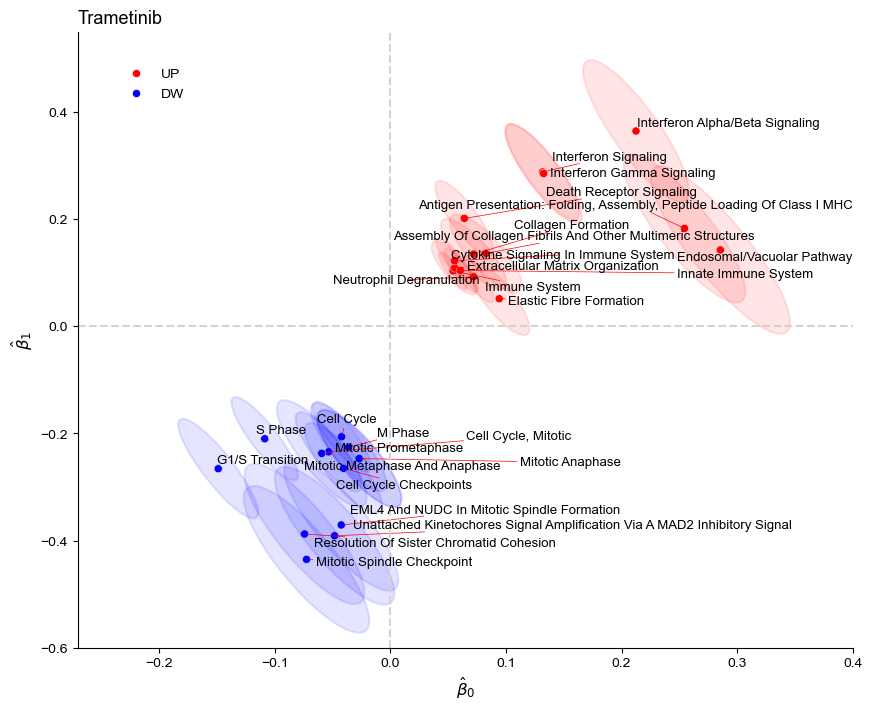

In [58]:
with plt.rc_context({'figure.figsize': (10, 8),'font.sans-serif':['Arial']}):
    fig, ax = plt.subplots()
    color_palette={'DW':'blue','UP':'red'}
    ax = sns.scatterplot(x='beta0',y='beta1',hue='types',data=res_df,s=35,palette=color_palette)
    leg = ax.legend( bbox_to_anchor=(0.05, 0.95),loc='upper left', borderaxespad=0)
    leg.get_frame().set_linewidth(0)   # remove border
    leg.set_title("") 
    plt.axhline(y=0, color='lightgrey', linestyle='--',linewidth=1.5)
    plt.axvline(x=0, color='lightgrey', linestyle='--',linewidth=1.5)
    texts = []
    for i in range(len(res_df)):
        beta0 = res_df.iloc[i]['beta0']
        beta1 = res_df.iloc[i]['beta1']
        cov_mtx = np.array([[res_df.iloc[i]['var_beta0'], res_df.iloc[i]['cov_beta']],
                            [res_df.iloc[i]['cov_beta'], res_df.iloc[i]['var_beta1']]])
        eigenvals, eigenvecs = np.linalg.eigh(cov_mtx)
        # draw ellipse
        order = eigenvals.argsort()[::-1]
        eigenvals = eigenvals[order]
        eigenvecs = eigenvecs[:, order]
        chi2_val = stats.chi2.ppf(0.95, df=2)
        semi_lens = np.sqrt(chi2_val) * np.sqrt(eigenvals)
        angle = np.degrees(np.arctan2(eigenvecs[1,0], eigenvecs[0,0]))

        ellipse = Ellipse(xy=(beta0, beta1),
                          width=semi_lens[0]*2,   # 主轴 *2
                          height=semi_lens[1]*2,  # 次轴 *2
                          angle=angle,
                          alpha=0.1,
                          color=color_palette[res_df.iloc[i]['types']],
                          linewidth=1.5)
        ax.add_artist(ellipse)
        texts.append(plt.text(res_df.iloc[i]['beta0'], res_df.iloc[i]['beta1'],res_df.iloc[i]['pathways_short'],fontsize=9.5))
        
    plt.xlim([-0.27,0.4]) #trametinib
    plt.ylim([-0.6,0.55]) #trametinib
    plt.xlabel(r'$\hat{\beta}_0$',fontsize=12)
    plt.ylabel(r'$\hat{\beta}_1$',fontsize=12)
    adjust_text(texts,  arrowprops=dict(arrowstyle="-", color='r', lw=0.5))
    plt.title(
    drug_name, 
    loc='left',fontsize=13
)
    sns.despine()
    #plt.savefig('all_figs/sens/{}.svg'.format(dataset_name), format='svg')
    plt.show()

In [107]:
adata=sc.read_h5ad('data/'+dataset_name+'_processed.h5ad')
sens_df=pd.read_csv('data/sensitivity_scores/'+dataset_name+'.csv',index_col=0)
sens_dict=sens_df.set_index('CCLE_ID').to_dict()['sens']
adata.obs['sens']=list(adata.obs['cell_type'].map(sens_dict))
nan_cell_lines = list(set(adata.obs[adata.obs.isna().any(axis=1)].cell_type.values))
adata2 = adata[~adata.obs.cell_type.isin(nan_cell_lines)]

In [108]:
dataset_dict=gp.get_library(name='Reactome_2022', organism='Human')

In [109]:
# UP example
search_pathway = 'Interferon Alpha/Beta Signaling R-HSA-909733'
geneset=dataset_dict[search_pathway]
geneset_search=list(set(geneset) & set(adata.var_names))
data_df=(pd.DataFrame([list((adata2[:,geneset_search].X.copy()).mean(axis=1).flatten()),
                       list(adata2.obs.condition),
                       list(adata2.obs.cell_type),
                      list(adata2.obs.sens)])).T
data_df.columns=['Yobs','pert','group','sens']
data_df["Yobs"] = pd.to_numeric(data_df["Yobs"])
data_df["sens"] = pd.to_numeric(data_df["sens"])
data_df = (
data_df.groupby(['pert', 'group'], as_index=False)
      .agg({
          'Yobs': 'mean',
          'sens': 'mean'
      })
)
data_df2 = data_df.copy()
pert_dict={'Trametinib':1,'control':0}
data_df2["pert"].replace(pert_dict, inplace=True)

In [110]:
res=scHPT.permute_test_cov_df2(data_df2,covs_columns=['sens'], 
                            n_perm=1000, gamma=0.001, n_search=[10, 30],random_state = 480)

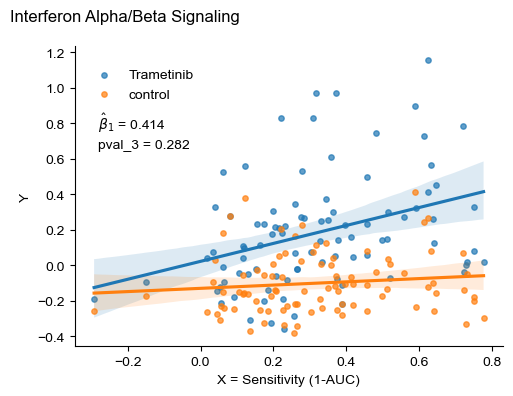

In [111]:
with plt.rc_context({'figure.figsize': (5, 3.5),'font.sans-serif':['Arial']}):
    g = sns.lmplot(
        data=data_df,
        x="sens",
        y="Yobs",
        hue="pert",
        height=4,   
        aspect=1,  
        scatter_kws={"s": 15, "alpha": 0.7}
    )
    g._legend.set_bbox_to_anchor((0.15, 0.85))  
    g._legend._loc = 2                    
    g._legend.get_frame().set_linewidth(0)  
    g._legend.set_title("")                 
    plt.text(-0.28,0.77,r'$\hat{\beta}_1$'+' = {}'.format(round(res[3][1][0],3)),fontsize=10)
    plt.text(-0.28,0.66,'pval_3 = {}'.format(round(res[0],3)),fontsize=10)
    g.fig.suptitle(search_pathway.split(' R-')[0], x=0.01, ha='left')  # 左对齐
    sns.despine()
    plt.ylabel('Y')
    plt.xlabel('X = Sensitivity (1-AUC)')
    plt.tight_layout()
    #plt.savefig('all_figs/sens/trametinib_up.svg', format='svg')
    plt.show()

In [112]:
# DW example
search_pathway = 'Cell Cycle Checkpoints R-HSA-69620'
geneset=dataset_dict[search_pathway]
geneset_search=list(set(geneset) & set(adata.var_names))
data_df=(pd.DataFrame([list((adata2[:,geneset_search].X.copy()).mean(axis=1).flatten()),
                       list(adata2.obs.condition),
                       list(adata2.obs.cell_type),
                      list(adata2.obs.sens)])).T
data_df.columns=['Yobs','pert','group','sens']
data_df["Yobs"] = pd.to_numeric(data_df["Yobs"])
data_df["sens"] = pd.to_numeric(data_df["sens"])
data_df = (
data_df.groupby(['pert', 'group'], as_index=False)
      .agg({
          'Yobs': 'mean',
          'sens': 'mean'
      })
)
data_df2 = data_df.copy()
pert_dict={'Trametinib':1,'control':0}
data_df2["pert"].replace(pert_dict, inplace=True)

In [142]:
res=scHPT.permute_test_cov_df2(data_df2,covs_columns=['sens'], 
                            n_perm=1000, gamma=0.001, n_search=[10, 30],random_state = 62)

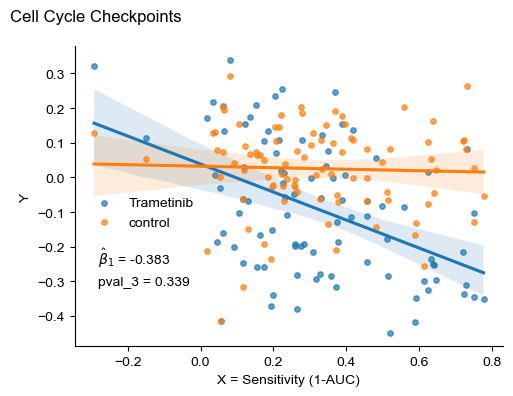

In [145]:
with plt.rc_context({'figure.figsize': (5, 3.5),'font.sans-serif':['Arial']}):
    g = sns.lmplot(
        data=data_df,
        x="sens",
        y="Yobs",
        hue="pert",
        height=4,   
        aspect=1,  
        scatter_kws={"s": 15, "alpha": 0.7}
    )
 
    g._legend.set_bbox_to_anchor((0.15, 0.53))  
    g._legend._loc = 2                    
    g._legend.get_frame().set_linewidth(0)  
    g._legend.set_title("")                 
    plt.text(-0.28,-0.25,r'$\hat{\beta}_1$'+' = {}'.format(round(res[3][1][0],3)),fontsize=10)
    plt.text(-0.28,-0.31,'pval_3 = {}'.format(round(res[0],3)),fontsize=10)
    g.fig.suptitle(search_pathway.split(' R-')[0], x=0.01, ha='left')  # 左对齐
    sns.despine()
    plt.ylabel('Y')
    plt.xlabel('X = Sensitivity (1-AUC)')
    plt.tight_layout()
    #plt.savefig('all_figs/sens/trametinib_dw.svg', format='svg')
    plt.show()